In [1]:
import pickle

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import arviz as az
import jax
from scipy.special import logsumexp
from scipy.stats import gamma

import numpyro
from numpyro.infer import MCMC, NUTS, SVI
import numpyro.distributions as dist

import infer

rng_key = jax.random.PRNGKey(42)

In [2]:
from run_number import *

df_bp = pd.read_csv("./data/human_number_game/human-data.txt", sep="\t")
df_bp = df_bp[df_bp["set"].isin(CONCEPT_SETS)].reset_index(drop=True)

X_s = sorted(set(df_bp["set"]))

obs_X = X_to_tensor(X_s)
obs_y = yn_to_tensor(X_s, df_bp, n_support=100)

# Likelihoods  p(X | h)  for each h
rule_concept_sets, interval_concept_sets = get_concept_sets()
rule_likes = [concept_set_to_likelihood(C) for C in rule_concept_sets]
int_likes = [concept_set_to_likelihood(C) for C in interval_concept_sets]
h_likelihoods = jnp.array(rule_likes + int_likes)

rule_ylikes = [concept_set_to_predict(C) for C in rule_concept_sets]
int_ylikes = [concept_set_to_predict(C) for C in interval_concept_sets]
y_predictives = jnp.array(rule_ylikes + int_ylikes)

model_kwargs = dict(
    y_predictives=y_predictives,
    h_likelihoods=h_likelihoods,
    obs_X=obs_X,
    obs_y=obs_y,
)

# model_kwargs = dict(
#     h_likelihoods=h_likelihoods,
#     h_embeddings=None,
#     obs_X=obs_X,
#     obs_y=obs_y,
#     prior_type='eb_number',
# )

In [12]:
X_ = obs_X[..., None]
X_likelihoods = (
    dist.Categorical(probs=h_likelihoods).mask(X_ != -1).log_prob(X_).sum(axis=-2)
)  ##### shape: (n_hypotheses, n_data)

model_kwargs = dict(
    y_predictives=y_predictives,
    X_likelihoods=X_likelihoods,
    obs_y=obs_y,
    # prior_type='eb_number',
)

In [71]:
cogsci16_orders = (
    list(range(28, 37))
    + list(range(19, 28))
    + [40, 41, 37, 38, 39]
    + list(range(9, 19))
    + list(range(9))
)

In [72]:
# rule_concepts[:9]        # powers of N
# rule_concepts[9:19]     # multiples
# rule_concepts[19:28]      # ends with digit
# rule_concepts[28:37]      # contains digit
# rule_concepts[37:]         # other

In [4]:
rule_concepts = [
    # Powers of n
    ("powers of 2", [2, 4, 8, 16, 32, 64]),
    ("powers of 3", [3, 9, 27, 81]),
    ("powers of 4", [4, 16, 64]),
    ("powers of 5", [5, 25]),
    ("powers of 6", [6, 36]),
    ("powers of 7", [7, 49]),
    ("powers of 8", [8, 64]),
    ("powers of 9", [9, 81]),
    ("powers of 10", [10, 100]),
    # Multiples of n
    ("multiples of 3", [i for i in range(1, 101) if i % 3 == 0]),
    ("multiples of 4", [i for i in range(1, 101) if i % 4 == 0]),
    ("multiples of 5", [i for i in range(1, 101) if i % 5 == 0]),
    ("multiples of 6", [i for i in range(1, 101) if i % 6 == 0]),
    ("multiples of 7", [i for i in range(1, 101) if i % 7 == 0]),
    ("multiples of 8", [i for i in range(1, 101) if i % 8 == 0]),
    ("multiples of 9", [i for i in range(1, 101) if i % 9 == 0]),
    ("multiples of 10", [i for i in range(1, 101) if i % 10 == 0]),
    ("multiples of 11", [i for i in range(1, 101) if i % 11 == 0]),
    ("multiples of 12", [i for i in range(1, 101) if i % 12 == 0]),
    # Ends with digit n
    # ('ends with digit 0', [i for i in range(1, 101) if i % 10 == 0]),
    ("ends with digit 1", [i for i in range(1, 101) if i % 10 == 1]),
    ("ends with digit 2", [i for i in range(1, 101) if i % 10 == 2]),
    ("ends with digit 3", [i for i in range(1, 101) if i % 10 == 3]),
    ("ends with digit 4", [i for i in range(1, 101) if i % 10 == 4]),
    ("ends with digit 5", [i for i in range(1, 101) if i % 10 == 5]),
    ("ends with digit 6", [i for i in range(1, 101) if i % 10 == 6]),
    ("ends with digit 7", [i for i in range(1, 101) if i % 10 == 7]),
    ("ends with digit 8", [i for i in range(1, 101) if i % 10 == 8]),
    ("ends with digit 9", [i for i in range(1, 101) if i % 10 == 9]),
    # Contains digit n
    # ('contains digit 0', [i for i in range(1, 101) if '0' in str(i)]),
    ("contains digit 1", [i for i in range(1, 101) if "1" in str(i)]),
    ("contains digit 2", [i for i in range(1, 101) if "2" in str(i)]),
    ("contains digit 3", [i for i in range(1, 101) if "3" in str(i)]),
    ("contains digit 4", [i for i in range(1, 101) if "4" in str(i)]),
    ("contains digit 5", [i for i in range(1, 101) if "5" in str(i)]),
    ("contains digit 6", [i for i in range(1, 101) if "6" in str(i)]),
    ("contains digit 7", [i for i in range(1, 101) if "7" in str(i)]),
    ("contains digit 8", [i for i in range(1, 101) if "8" in str(i)]),
    ("contains digit 9", [i for i in range(1, 101) if "9" in str(i)]),
    # is Prime
    (
        "prime",
        [
            1,
            2,
            3,
            5,
            7,
            11,
            13,
            17,
            19,
            23,
            29,
            31,
            37,
            41,
            43,
            47,
            53,
            59,
            61,
            67,
            71,
            73,
            79,
            83,
            89,
            97,
        ],
    ),
    ### [i for i in range(1, 101) if not any([i == (j1 * j2) for j1 in range(1, i) for j2 in range(1, i)])],
    # is even/odd
    ("even", [i for i in range(1, 101) if i % 2 == 0]),
    ("odd", [i for i in range(1, 101) if i % 2 == 1]),
    # squares/cubes
    ("squares x^2", [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]),
    ("cubes x^3", [1, 8, 27, 64]),
]

rule_concept_names = [name for name, _ in rule_concepts]

## model 2a

In [54]:
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_mini.pk', 'rb'))
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_x-h-y.pk', 'rb'))
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_test_condition.pk', 'rb'))
mcmc = pickle.load(open("./data/bp_number_game/mcmc_test_2a-full2.pk", "rb"))

samples = mcmc.get_samples()

In [55]:
samples["p_rules"].shape

(3000, 42)

In [49]:
def prior_ng(p_mix, p_rules):
    n_samples, n_rules = p_rules.shape
    p_mix = p_mix[:, None]

    # Normalize gamma sampled rule probabilities
    p_rules = p_rules / p_rules.sum(axis=-1, keepdims=True)

    # Organize priors into a flat array
    h_prior = jnp.zeros((n_samples, n_rules + 5050))
    h_prior = h_prior.at[:, :n_rules].set(p_mix * p_rules)
    h_prior = h_prior.at[:, n_rules:].set((1 - p_mix) * (1 / 5050))

    h_prior = h_prior / h_prior.sum(axis=-1, keepdims=True)
    return h_prior


def compute_predictive(X_likelihoods, y_predictives, samples):

    h_prior = prior_ng(
        samples["p_mix"], samples["p_rules"]
    )  # shape: (n_samples, n_hypotheses)

    h_prior = h_prior[:, None, :]
    X_likelihoods = np.exp(X_likelihoods)[None, :, :]
    samples_predict = (
        X_likelihoods * h_prior
    ) @ y_predictives  # shape: (n_samples, n_data, n_support)

    hyper_mix = dist.Gamma(2, 1).log_prob(samples["p_mix"])
    hyper_rules = dist.Gamma(2, 1).log_prob(samples["p_rules"]).sum(axis=1)
    hyper_mix -= logsumexp(hyper_mix)
    hyper_rules -= logsumexp(hyper_rules)
    hyper_prior = jnp.exp(hyper_mix + hyper_rules)

    post_predict = hyper_prior[:, None, None] * samples_predict
    return post_predict


post_predict = compute_predictive(X_likelihoods, y_predictives, samples)

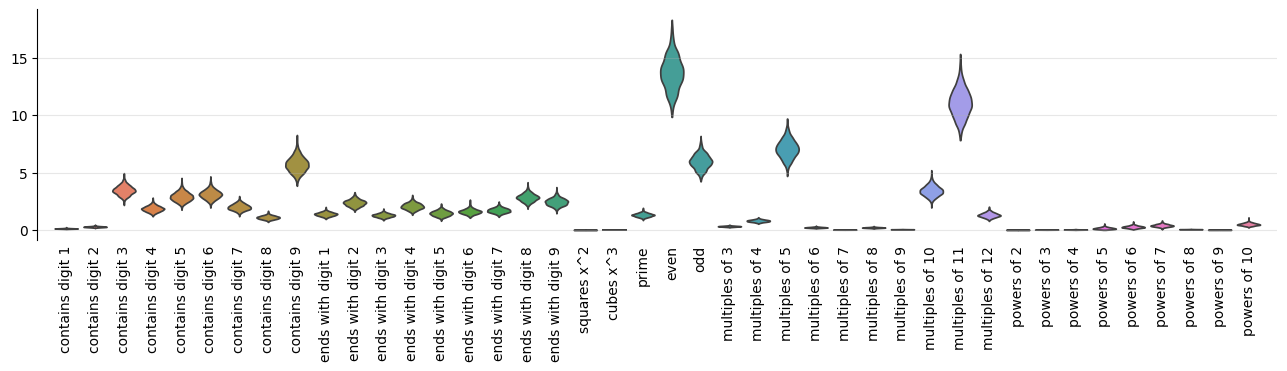

In [74]:
plt.rcParams["figure.figsize"] = (16, 3)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules][:, cogsci16_orders], inner=None, cut=0)
plt.xticks(
    range(n_rules), np.array(rule_concept_names[:n_rules])[cogsci16_orders], rotation=90
)

###### sns.violinplot(samples['p_rules'][:, :n_rules], inner=None, cut=0)         #### WITHOUT COGSCI ORDERING
###### plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90);

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='gold', s=100, marker='*', linewidth=.5)

# plt.hlines(0, 0, 42)
plt.grid(alpha=0.3, axis="y")
plt.tick_params(axis="x", which="both", length=0)

# plt.ylim(-1, 5)
plt.xlim(-1, n_rules)

sns.despine(bottom=True)

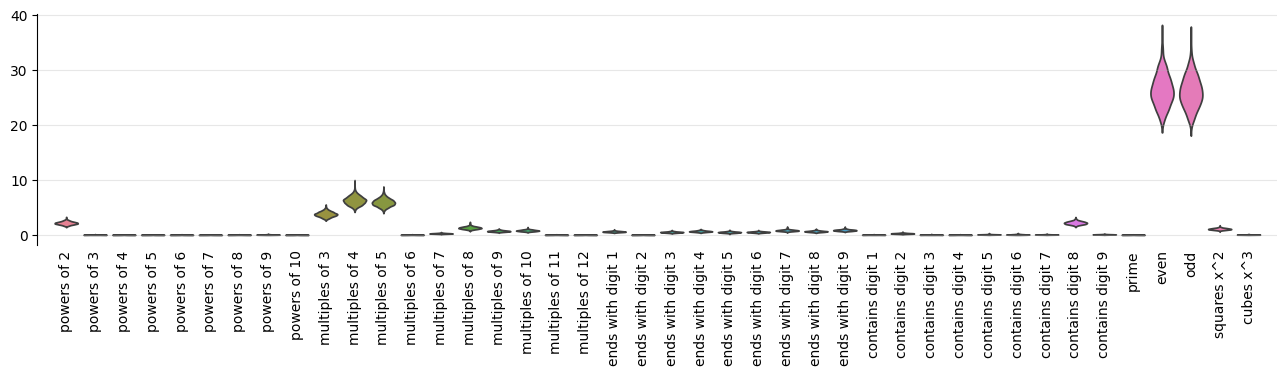

In [29]:
plt.rcParams["figure.figsize"] = (16, 3)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules], inner=None, cut=0)
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='gold', s=100, marker='*', linewidth=.5)

# plt.hlines(0, 0, 42)
plt.grid(alpha=0.3, axis="y")
plt.tick_params(axis="x", which="both", length=0)

# plt.ylim(-1, 30)
plt.xlim(-1, n_rules)

sns.despine(bottom=True)

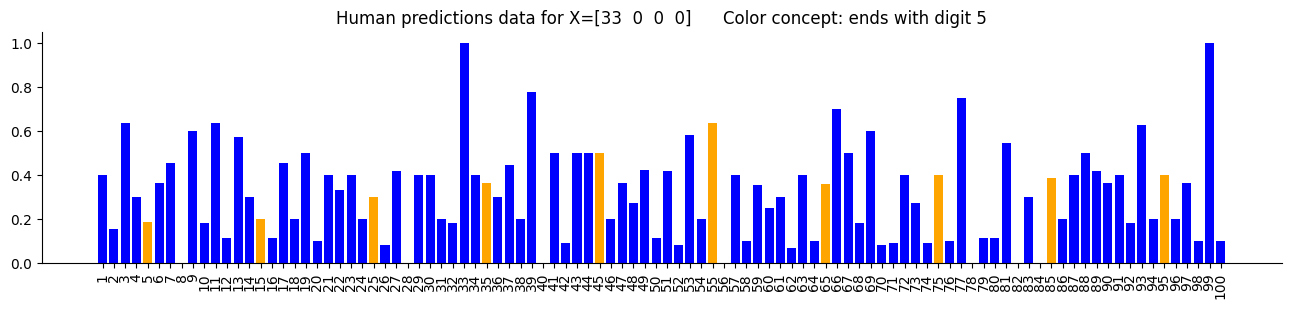

In [53]:
plt.rcParams["figure.figsize"] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = 10  # 21/24   # 20   3
c_idx = 23  # 26   10

y_yes, y_total = obs_y[..., 0], obs_y[..., 1]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_yes[i] / y_total[i], color=color)
plt.xticks(range(100), range(1, 101), rotation=90)

plt.title(
    f"Human predictions data for X={obs_X[i] + 1}      Color concept: {concept_name}"
)
sns.despine()

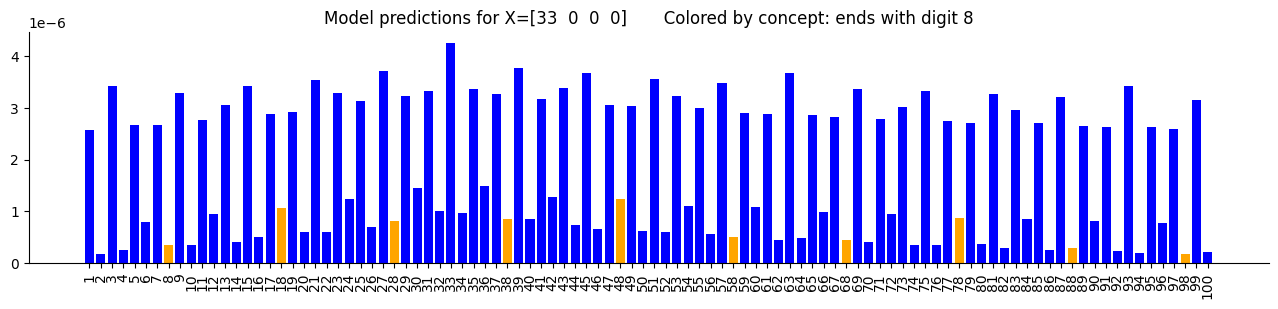

In [39]:
plt.rcParams["figure.figsize"] = (16, 3)

c_idx = 26
data_idx = 10


# n_data, n_hypotheses = X_likelihoods.shape
# prior = np.ones(n_hypotheses)

# post_predict = np.exp(X_likelihoods) * prior @ y_predictives

concept_name, _, concept_colors = color_concept(c_idx)
plt.bar(range(100), post_predict.sum(axis=0)[data_idx], color=concept_colors)
plt.xticks(range(100), range(1, 101), rotation=90)


plt.title(
    f"Model predictions for X={obs_X[data_idx] + 1}       Colored by concept: {concept_name}"
)
sns.despine()

# MCMC samples

In [5]:
numpyro.set_host_device_count(12)

In [5]:
# get samples for discrete variables
#   https://github.com/pyro-ppl/numpyro/issues/1121#issuecomment-897363003


def get_posterior_samples(model, samples, model_kwargs):
    predictive = numpyro.infer.Predictive(
        model, samples, infer_discrete=True, return_sites=["h"]
    )
    discrete_samples = predictive(rng_key, **model_kwargs)

    ll = numpyro.infer.util.log_likelihood(
        model=model,
        posterior_samples=samples | discrete_samples,
        parallel=True,
        **model_kwargs
    )

    ll_X = ll["X"].sum(axis=[1, 2])
    ll_y = ll["y"].sum(axis=[1, 2])

    prior_mix = dist.Gamma(2, 1).log_prob(samples["p_mix"])
    prior_rules = dist.Gamma(2, 1).log_prob(samples["p_rules"]).sum(axis=1)
    # prior_mix = gamma.logpdf(np.array(samples['p_mix']), 2, scale=1)
    # prior_rules = gamma.logpdf(np.array(samples['p_rules']), 2, scale=1).sum(axis=1)

    ll_X -= logsumexp(ll_X)
    ll_y -= logsumexp(ll_y)
    prior_mix -= logsumexp(prior_mix)
    prior_rules -= logsumexp(prior_rules)

    posterior = ll_X + ll_y + prior_mix + prior_rules
    return posterior

In [6]:
mcmc = pickle.load(open("./data/bp_number_game/mcmc.pk", "rb"))
samples = mcmc.get_samples()

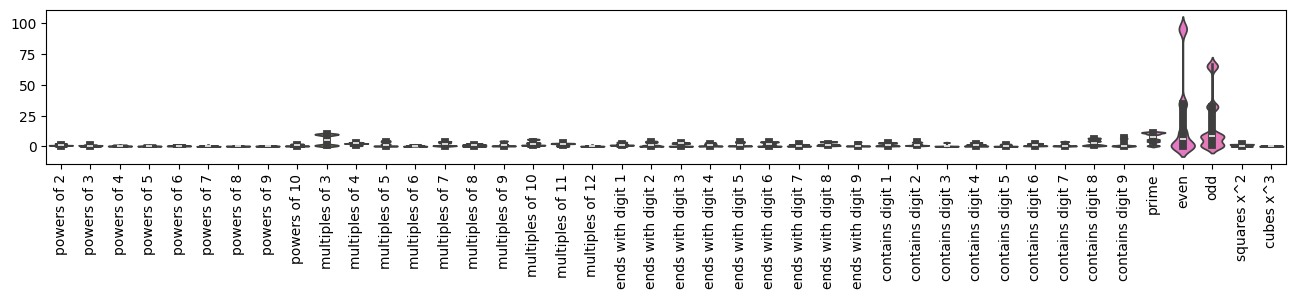

In [81]:
plt.rcParams["figure.figsize"] = (16, 2)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules])
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='red', s=100)

# plt.ylim(0, 10)

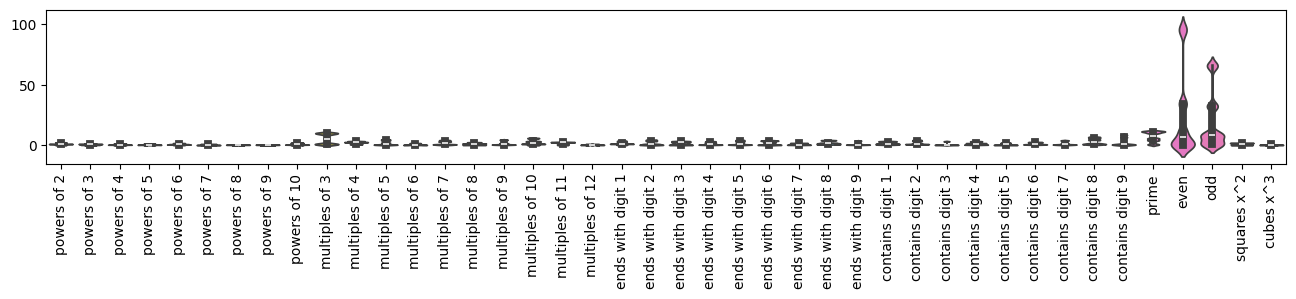

In [25]:
plt.rcParams["figure.figsize"] = (16, 2)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules])
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='red', s=100)

# plt.ylim(0, 10)

### mcmc mini

In [10]:
# get samples for discrete variables
#   https://github.com/pyro-ppl/numpyro/issues/1121#issuecomment-897363003


def get_posterior_samples(model, samples, model_kwargs):
    predictive = numpyro.infer.Predictive(
        model, samples, infer_discrete=True, return_sites=["h"]
    )
    discrete_samples = predictive(rng_key, **model_kwargs)

    ll = numpyro.infer.util.log_likelihood(
        model=model,
        posterior_samples=samples | discrete_samples,
        parallel=True,
        **model_kwargs
    )

    # ll_X = ll['X'].sum(axis=[1, 2])
    ll_y = ll["y"].sum(axis=[1, 2])

    prior_mix = dist.Gamma(2, 1).log_prob(samples["p_mix"])
    prior_rules = dist.Gamma(2, 1).log_prob(samples["p_rules"]).sum(axis=1)
    # prior_mix = gamma.logpdf(np.array(samples['p_mix']), 2, scale=1)
    # prior_rules = gamma.logpdf(np.array(samples['p_rules']), 2, scale=1).sum(axis=1)

    # ll_X -= logsumexp(ll_X)
    ll_y -= logsumexp(ll_y)
    prior_mix -= logsumexp(prior_mix)
    prior_rules -= logsumexp(prior_rules)

    posterior = ll_y + prior_mix + prior_rules
    return posterior

In [16]:
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_mini.pk', 'rb'))
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_x-h-y.pk', 'rb'))
# mcmc = pickle.load(open('./data/bp_number_game/mcmc_test_condition.pk', 'rb'))
mcmc = pickle.load(open("./data/bp_number_game/mcmc_test_2a.pk", "rb"))

samples = mcmc.get_samples()

In [23]:
model = infer.number_bpl_model_2a
posterior = get_posterior_samples(model, samples, model_kwargs)

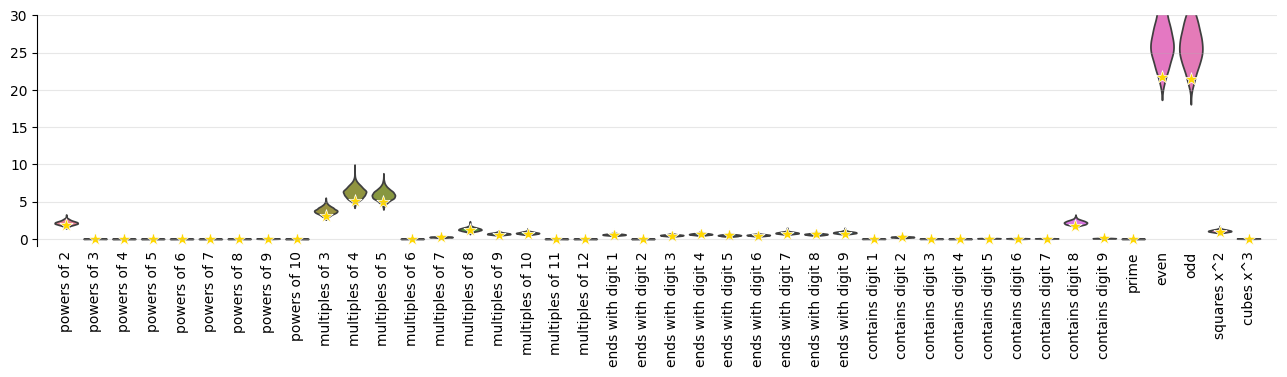

In [18]:
plt.rcParams["figure.figsize"] = (16, 3)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules], inner=None, cut=0)
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

map_idx = posterior.argmax()
map_probs = samples["p_rules"][map_idx, :n_rules]
sns.scatterplot(
    x=range(n_rules), y=map_probs, color="gold", s=100, marker="*", linewidth=0.5
)

# plt.hlines(0, 0, 42)
plt.grid(alpha=0.3, axis="y")
plt.tick_params(axis="x", which="both", length=0)

plt.ylim(-1, 30)
plt.xlim(-1, n_rules)

sns.despine(bottom=True)

##### predictions

In [20]:
def color_concept(c_idx):
    concept_name, C = rule_concepts[c_idx]
    colors = [("orange" if c in C else "blue") for c in range(1, 101)]
    return concept_name, C, colors

In [138]:
list(enumerate(obs_X))

[(0, Array([ 9, 49, 99, -1], dtype=int32)),
 (1, Array([ 9, 79, -1, -1], dtype=int32)),
 (2, Array([15, -1, -1, -1], dtype=int32)),
 (3, Array([15, 31,  1,  7], dtype=int32)),
 (4, Array([15, 53, -1, -1], dtype=int32)),
 (5, Array([15,  7, -1, -1], dtype=int32)),
 (6, Array([ 1,  7, -1, -1], dtype=int32)),
 (7, Array([19,  7, 83, 99], dtype=int32)),
 (8, Array([21, 61, 25, 81], dtype=int32)),
 (9, Array([31,  3, 15, -1], dtype=int32)),
 (10, Array([32, -1, -1, -1], dtype=int32)),
 (11, Array([32, 16,  4,  8], dtype=int32)),
 (12, Array([32,  2, 64, -1], dtype=int32)),
 (13, Array([32,  4, 18, -1], dtype=int32)),
 (14, Array([32,  8, -1, -1], dtype=int32)),
 (15, Array([35, 44, 53, 80], dtype=int32)),
 (16, Array([36, 56, -1, -1], dtype=int32)),
 (17, Array([ 3, 15, 11, -1], dtype=int32)),
 (18, Array([ 3, 63, 24, 80], dtype=int32)),
 (19, Array([45, 75, 65, -1], dtype=int32)),
 (20, Array([47, 77, 37, 97], dtype=int32)),
 (21, Array([ 4, 64, -1, -1], dtype=int32)),
 (22, Array([ 4, 76,

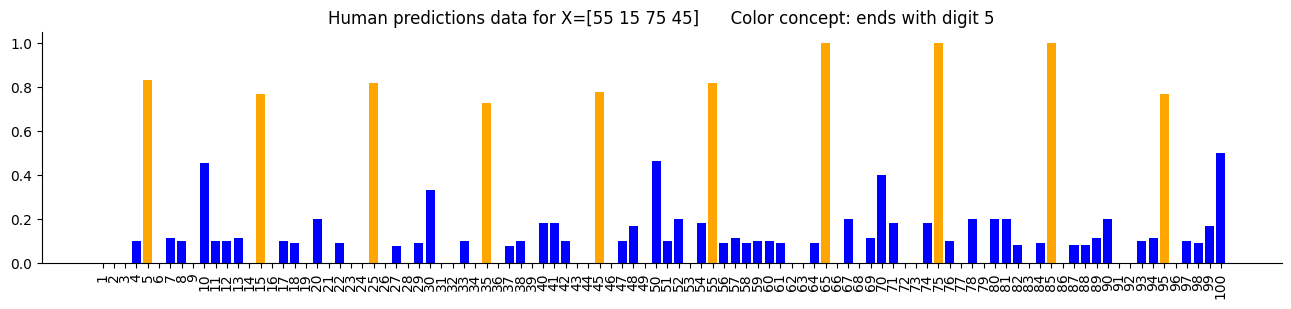

In [21]:
plt.rcParams["figure.figsize"] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = 24  # 21/24   # 20   3
c_idx = 23  # 26   10

y_yes, y_total = obs_y[..., 0], obs_y[..., 1]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_yes[i] / y_total[i], color=color)
plt.xticks(range(100), range(1, 101), rotation=90)

plt.title(
    f"Human predictions data for X={obs_X[i] + 1}      Color concept: {concept_name}"
)
sns.despine()

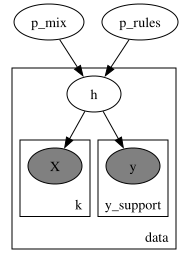

In [17]:
numpyro.render_model(model, model_kwargs=model_kwargs)

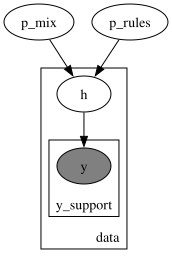

In [12]:
numpyro.render_model(model, model_kwargs=model_kwargs)

In [24]:
# model = infer.number_bpl_model_flat1
# model = numpyro.handlers.condition(config_enumerate(infer.number_bpl_model_2a), {'X': obs_X})

predictive = numpyro.infer.Predictive(
    model, samples, infer_discrete=True, return_sites=["y", "h"]
)  # , 'y_pred'
discrete_samples = predictive(
    rng_key, **{k: v for k, v in model_kwargs.items() if k != "obs_y"}
)

In [25]:
samples["p_mix"].mean()

Array(0.85034, dtype=float32)

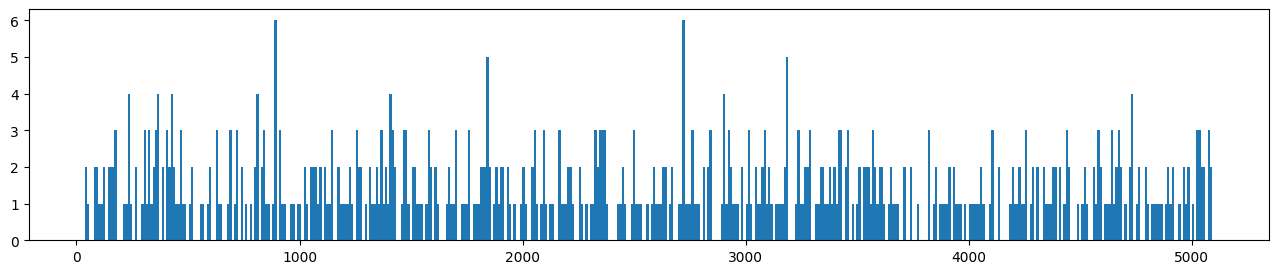

In [21]:
plt.hist(discrete_samples["h"][:, 20, 0], bins=500)

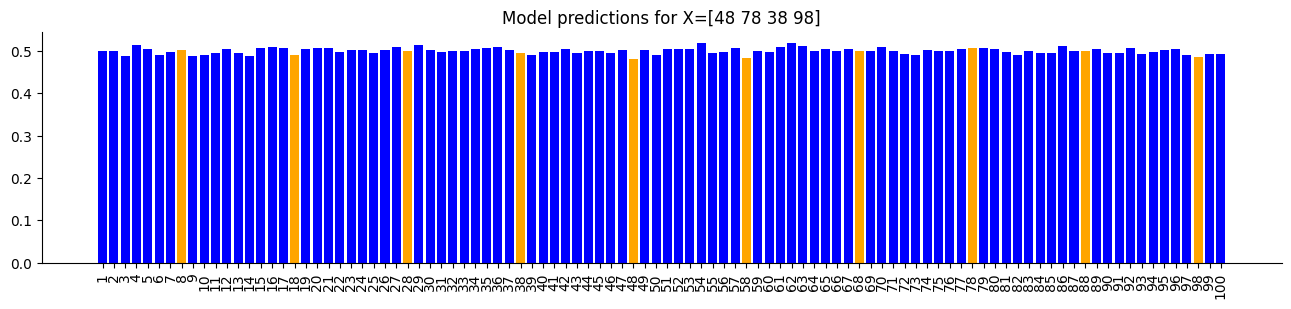

In [27]:
plt.rcParams["figure.figsize"] = (16, 3)

# y_est = jnp.max(samples['y'], axis=0)
# y_prob = samples['y_prob'].mean(axis=0)
# y_prob = jnp.mean(discrete_samples['y_pred'], axis=0)
y_est = jnp.mean(discrete_samples["y"], axis=0)


i = 20
plt.bar(range(100), y_est[i] / 30, color=color_concept(26)[2])
# plt.bar(range(100),  y_prob[i])
plt.xticks(range(100), range(1, 101), rotation=90)


plt.title(f"Model predictions for X={obs_X[i] + 1}")
sns.despine()

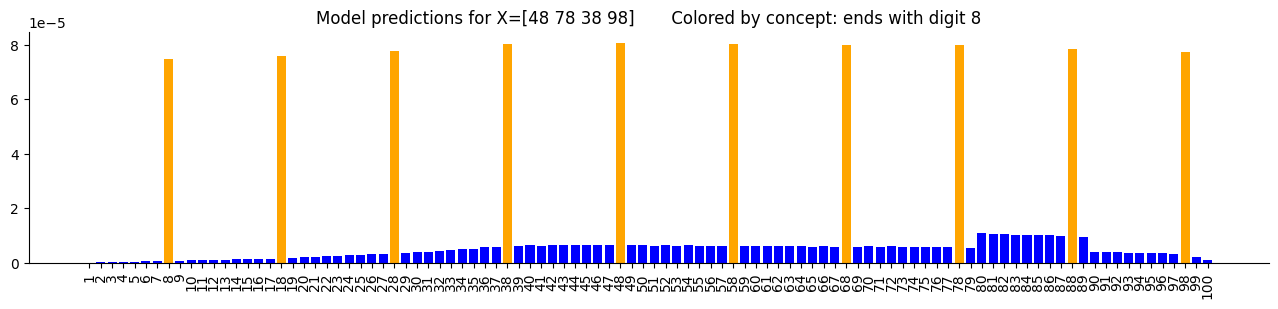

In [50]:
plt.rcParams["figure.figsize"] = (16, 3)

prior = np.ones(n_hypotheses)
c_idx = 26
data_idx = 20


n_data, n_hypotheses = X_likelihoods.shape
post_predict = np.exp(X_likelihoods) * prior @ y_predictives

concept_name, _, concept_colors = color_concept(c_idx)
plt.bar(range(100), post_predict[data_idx], color=concept_colors)
plt.xticks(range(100), range(1, 101), rotation=90)


plt.title(
    f"Model predictions for X={obs_X[data_idx] + 1}       Colored by concept: {concept_name}"
)
sns.despine()

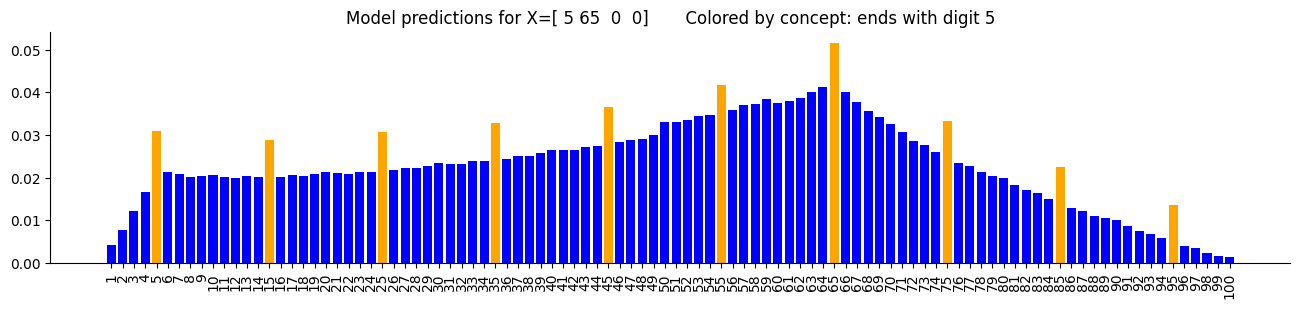

In [180]:
plt.rcParams["figure.figsize"] = (16, 3)

prior = np.ones(n_hypotheses)
c_idx = 23
data_idx = 21


n_data, n_hypotheses = X_likelihoods.shape
post_predict = np.exp(X_likelihoods) * prior @ y_predictives

concept_name, _, concept_colors = color_concept(c_idx)
plt.bar(range(100), post_predict[data_idx], color=concept_colors)
plt.xticks(range(100), range(1, 101), rotation=90)


plt.title(
    f"Model predictions for X={obs_X[data_idx] + 1}       Colored by concept: {concept_name}"
)
sns.despine()

In [55]:
from scipy.special import softmax

In [60]:
softmax(np.exp(X_likelihoods) * prior, axis=-1).shape

(50, 5092)

In [61]:
softmax(np.exp(X_likelihoods) * prior, axis=-1).sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [74]:
np.exp(X_likelihoods[data_idx][:n_rules]) / np.exp(
    X_likelihoods[data_idx][:n_rules]
).sum()

array([1.3480150e-08, 1.3480150e-08, 1.3480150e-08, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08, 1.3480150e-08, 1.3480150e-08,
       1.3480150e-08, 1.0775326e-05, 4.9876559e-07, 1.3480150e-08,
       4.4181994e-05, 8.8006180e-07, 1.0244904e-06, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08, 1.5299955e-06, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08, 1.3480150e-08, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08, 9.2440069e-01, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08, 6.5201351e-07, 6.5201351e-07,
       1.3480150e-08, 1.3480150e-08, 6.5201351e-07, 7.3780611e-02,
       6.5201351e-07, 1.3480150e-08, 1.7567463e-03, 1.3480150e-08,
       1.3480150e-08, 1.3480150e-08], dtype=float32)

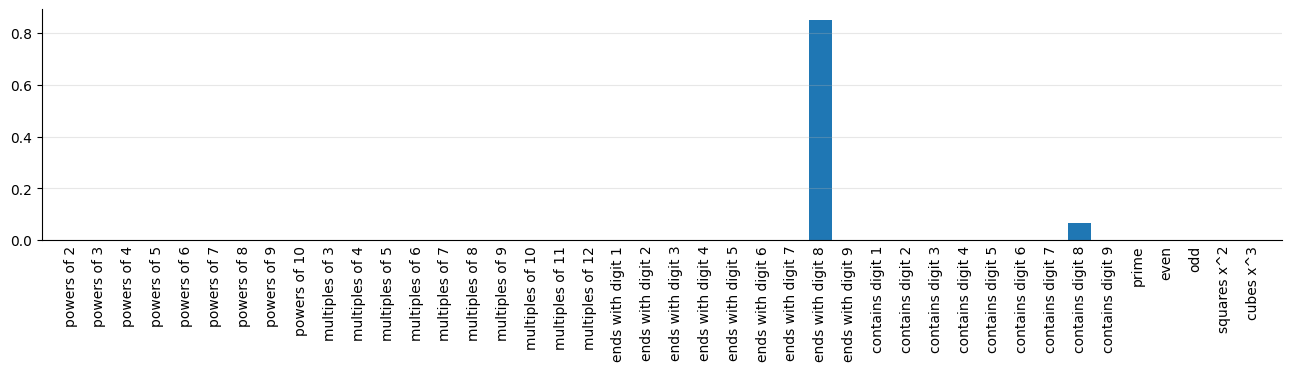

In [122]:
plt.rcParams["figure.figsize"] = (16, 3)


n_rules = 42
data_idx = 20

prior = np.ones(n_hypotheses)  # np.random.uniform(0, 1, n_hypotheses)
prior /= prior.sum()

h_post = np.exp(X_likelihoods[data_idx]) * prior
h_post /= h_post.sum()


plt.bar(range(n_rules), h_post[:n_rules])
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='gold', s=100, marker='*', linewidth=.5)

# plt.hlines(0, 0, 42)
plt.grid(alpha=0.3, axis="y")
plt.tick_params(axis="x", which="both", length=0)

# plt.ylim(-1, 20)
plt.xlim(-1, n_rules)

sns.despine()

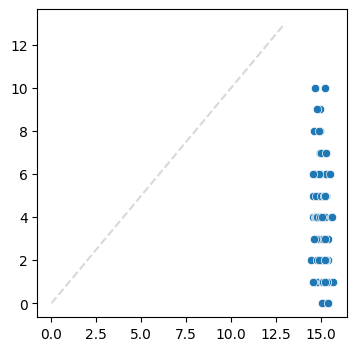

In [27]:
plt.rcParams["figure.figsize"] = (4, 4)

y_prob = jnp.mean(discrete_samples["y"], axis=0)
y_human_prob = obs_y[..., 0]  # / obs_y[..., 1]

max_y_total = y_human_prob[i].max()
plt.plot([0, max_y_total], [0, max_y_total], ls="--", color="grey", alpha=0.3)


i = 10
sns.scatterplot(x=y_prob[i], y=y_human_prob[i])

# Viz prior samples

In [39]:
samples["p_rules"].shape

(6000, 44)

In [40]:
pyro_data = az.from_pyro(
    mcmc,
    prior=prior,
    # posterior_predictive=posterior_predictive,
    coords={"school": np.arange(eight_school_data["J"])},
    dims={"theta": ["school"]},
)
pyro_data

NameError: name 'prior' is not defined

In [19]:
list(enumerate(rule_concept_names))

[(0, 'powers of 2'),
 (1, 'powers of 2'),
 (2, 'powers of 2'),
 (3, 'powers of 2'),
 (4, 'powers of 2'),
 (5, 'powers of 2'),
 (6, 'powers of 2'),
 (7, 'powers of 2'),
 (8, 'powers of 2'),
 (9, 'multiples of 3'),
 (10, 'multiples of 4'),
 (11, 'multiples of 5'),
 (12, 'multiples of 6'),
 (13, 'multiples of 7'),
 (14, 'multiples of 8'),
 (15, 'multiples of 9'),
 (16, 'multiples of 10'),
 (17, 'multiples of 11'),
 (18, 'multiples of 12'),
 (19, 'ends with digit 0'),
 (20, 'ends with digit 1'),
 (21, 'ends with digit 2'),
 (22, 'ends with digit 3'),
 (23, 'ends with digit 4'),
 (24, 'ends with digit 5'),
 (25, 'ends with digit 6'),
 (26, 'ends with digit 7'),
 (27, 'ends with digit 8'),
 (28, 'ends with digit 9'),
 (29, 'contains digit 0'),
 (30, 'contains digit 1'),
 (31, 'contains digit 2'),
 (32, 'contains digit 3'),
 (33, 'contains digit 4'),
 (34, 'contains digit 5'),
 (35, 'contains digit 6'),
 (36, 'contains digit 7'),
 (37, 'contains digit 8'),
 (38, 'contains digit 9'),
 (39, 'pr

(0.0, 10.0)

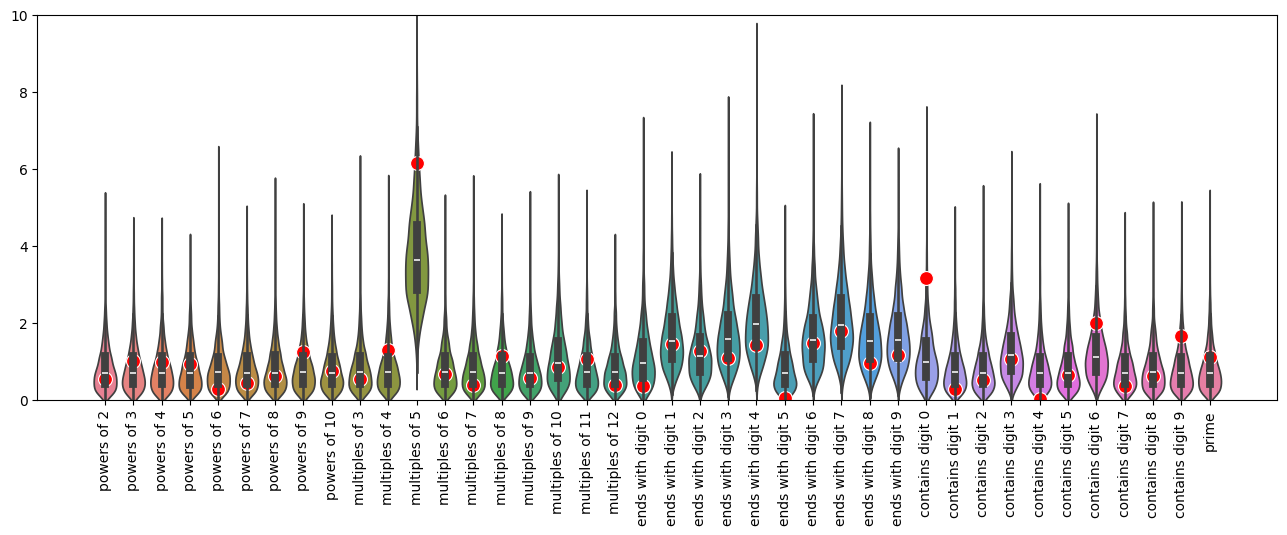

In [75]:
plt.rcParams["figure.figsize"] = (16, 5)

n_rules = 40

sns.violinplot(samples["p_rules"][:, :n_rules])
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# sns.scatterplot(x=range(n_rules), y=map_probs, color='red', s=100)

plt.ylim(0, 10)

# MAP estimate

In [5]:
samples

{'p_mix': Array([0.47996667, 0.45266938, 0.50775415, ..., 0.44601992, 0.49066088,
        0.45520204], dtype=float32),
 'p_rules': Array([[2.34325305e-01, 3.26686978e+00, 1.25227618e+00, ...,
         1.66956844e+01, 3.41142803e-01, 7.97849536e-01],
        [3.53071451e-01, 2.41872168e+00, 1.06861484e+00, ...,
         1.54533291e+01, 7.09666133e-01, 1.46558511e+00],
        [1.29463720e+00, 1.34960413e-01, 6.26858890e-01, ...,
         1.51334457e+01, 1.00923181e+00, 2.40551680e-01],
        ...,
        [2.21067630e-02, 8.02801132e-01, 3.74468923e-01, ...,
         1.81976604e+01, 8.48762155e-01, 2.03486156e+00],
        [1.83451995e-02, 6.36677206e-01, 2.79128283e-01, ...,
         1.64027672e+01, 1.21048951e+00, 7.78548121e-01],
        [1.45970285e-02, 7.79008806e-01, 1.52689561e-01, ...,
         1.45525932e+01, 4.90818471e-01, 1.56359506e+00]], dtype=float32)}

In [33]:
# get samples for discrete variables
#   https://github.com/pyro-ppl/numpyro/issues/1121#issuecomment-897363003
predictive = numpyro.infer.Predictive(
    number_bpl_model_flat, samples, infer_discrete=True
)
discrete_samples = predictive(rng_key, **model_kwargs)

In [34]:
ll = numpyro.infer.util.log_likelihood(
    model=number_bpl_model_flat,
    posterior_samples=samples | discrete_samples,
    **model_kwargs
)

In [35]:
ll_X = ll["X"].sum(axis=[1, 2])
ll_y = ll["y"].sum(axis=[1, 2])

prior_mix = dist.Gamma(2, 1).log_prob(samples["p_mix"])
prior_rules = dist.Gamma(2, 1).log_prob(samples["p_rules"]).sum(axis=1)

ll_X -= logsumexp(ll_X)
ll_y -= logsumexp(ll_y)
prior_mix -= logsumexp(prior_mix)
prior_rules -= logsumexp(prior_rules)

prior_ratio = 0.7

# posterior = ll_X ** (1 - prior_ratio) + ll_y ** (1 - prior_ratio) + prior_mix ** prior_ratio + prior_rules ** prior_ratio
posterior = ll_X + ll_y + prior_mix + prior_rules

In [20]:
ll["X"].min()

Array(-6.9077554, dtype=float32)

In [26]:
ll_y.min()

Array(-426670.97, dtype=float32)

In [9]:
{k: type(discrete_samples[k]) for k in discrete_samples.keys()}

{'X': jaxlib.xla_extension.ArrayImpl,
 'h': jaxlib.xla_extension.ArrayImpl,
 'y': jaxlib.xla_extension.ArrayImpl}

In [8]:
discrete_samples["X"][0, :, :].shape

(255, 4)

In [ ]:
# np.array_equal(np.array(discrete_samples['X'][0, :, :]),
#                model_kwargs['obs_X'])

In [89]:
samples["p_rules"].shape

(6000, 42)

In [16]:
type(ll["X"])

jaxlib.xla_extension.ArrayImpl

In [14]:
ll["X"].shape, ll["y"].shape

((6000, 255, 4), (6000, 255, 100))

In [24]:
{k: v.shape for k, v in samples.items()}

{'p_mix': (6000,), 'p_rules': (6000, 44)}

mixture param:  0.46621963


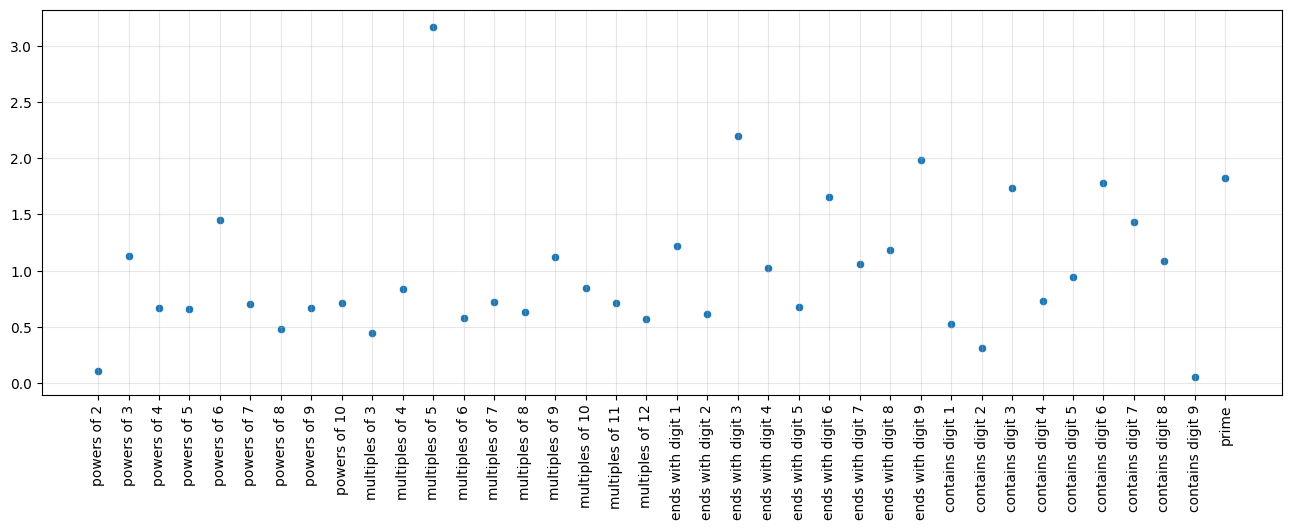

In [52]:
map_idx = posterior.argmax()

print("mixture param: ", samples["p_mix"][map_idx])


n_rules = 38

map_probs = samples["p_rules"][map_idx, :n_rules]

plt.grid(alpha=0.3)  # True, axis='x')
sns.scatterplot(x=range(n_rules), y=map_probs)


plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)
# plt.ylim(0, 10);
# plt.yscale('log')

(0.0, 10.0)

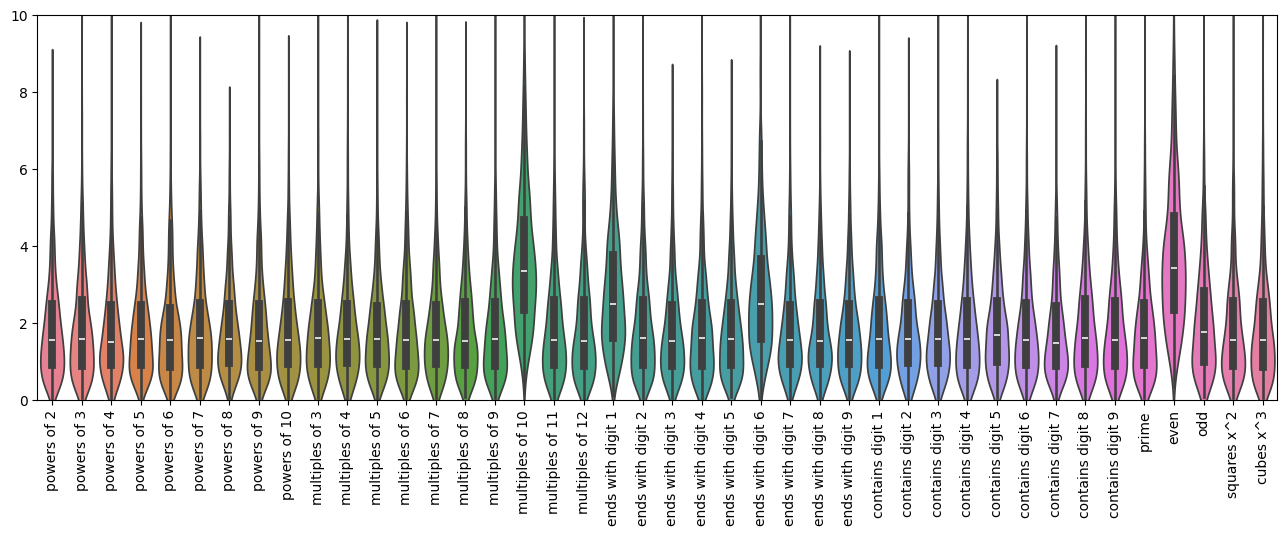

In [9]:
plt.rcParams["figure.figsize"] = (16, 5)


n_rules = 42

sns.violinplot(samples["p_rules"][:, :n_rules])
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90)

# map_idx = posterior.argmax()
# map_probs = samples['p_rules'][map_idx, :n_rules]
# sns.scatterplot(x=range(n_rules), y=map_probs, color='red', s=100)

plt.ylim(0, 10)

mixture param:  0.47712263


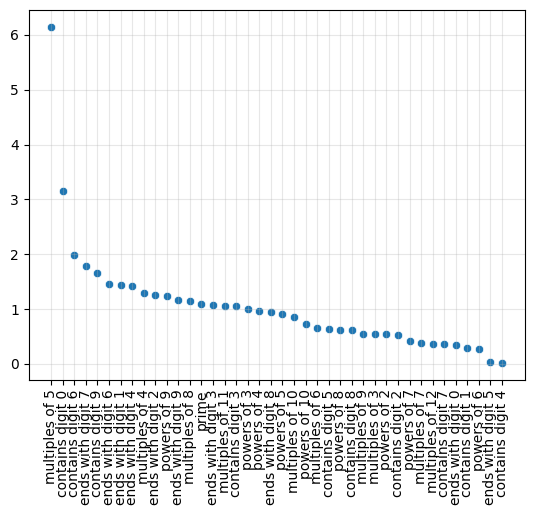

In [61]:
map_idx = posterior.argmax()
posterior[map_idx]

print("mixture param: ", samples["p_mix"][map_idx])


n_rules = 40

map_probs = samples["p_rules"][map_idx, :n_rules]
sorted_idxs = map_probs.argsort(descending=True)

plt.grid(alpha=0.3)  # True, axis='x')
sns.scatterplot(x=range(n_rules), y=map_probs[sorted_idxs])


plt.xticks(range(n_rules), np.array(rule_concept_names)[sorted_idxs], rotation=90)
# plt.ylim(0, 10);
# plt.yscale('log')

(array([  10.,   35.,  216.,  703., 1348., 1574., 1262.,  621.,  192.,
          39.]),
 array([-428770.46875, -426454.96875, -424139.5    , -421824.     ,
        -419508.53125, -417193.03125, -414877.53125, -412562.0625 ,
        -410246.5625 , -407931.09375, -405615.59375]),
 <BarContainer object of 10 artists>)

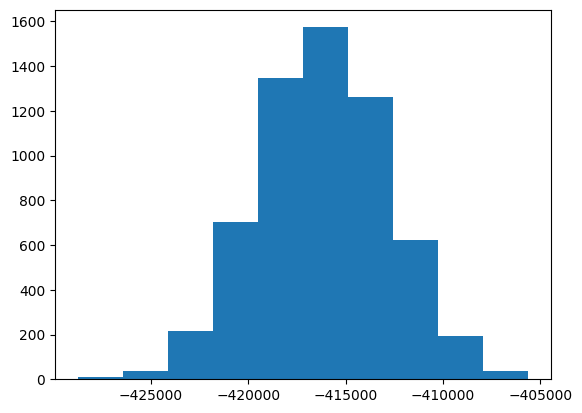

In [63]:
plt.hist(posterior)

In [34]:
prior_mix.shape

(6000,)

# SVI

In [4]:
n_cpu = 10
numpyro.set_host_device_count(n_cpu)

obs_X.shape

(50, 4)

In [5]:
guide = numpyro.infer.autoguide.AutoDelta(number_bpl_model_flat)
model = number_bpl_model_flat  # numpyro.handlers.block(number_bpl_model_flat, lambda site: site['name'] == 'h')

subsample_size = 100
num_svi_steps = 2000

optimizer = numpyro.optim.Adam(step_size=1e-2)
svi = numpyro.infer.SVI(model, guide, optimizer, loss=numpyro.infer.TraceEnum_ELBO())
# num_particles=n_cpu))   # , init_strategy=numpyro.infer.init_to_value()

svi_result = svi.run(
    rng_key, num_svi_steps, subsample_size=subsample_size, **model_kwargs
)
params, losses = svi_result.params, svi_result.losses


# ref_params = {"theta": params["theta_auto_loc"]}
# autoguide_map.median(data) #["latent_fairness"].item()

ValueError: Continuous inference cannot handle discrete sample site 'h'.

In [5]:
def guide(*args, **kwargs):
    # https://num.pyro.ai/en/stable/examples/toy_mixture_model_discrete_enumeration.html
    n_rules = 42
    p_mix_param = numpyro.param("p_mix_auto_loc", 0.5)
    p_mix = numpyro.sample("p_mix", dist.Delta(p_mix_param))  # dist.Beta(2, 2))

    p_rules_param = numpyro.param("p_rules_auto_loc", jnp.ones(n_rules) * 2)
    p_rules = numpyro.sample(
        "p_rules", dist.Delta(p_rules_param).to_event(1)
    )  # Dirichlet(p_rules_param))
    # numpyro.sample('p_rules', dist.Gamma(2, 1).expand([n_rules]).to_event(1))


# guide = numpyro.infer.autoguide.AutoDelta(number_bpl_model_flat)
model = number_bpl_model_flat  # numpyro.handlers.block(number_bpl_model_flat, lambda site: site['name'] == 'h')

subsample_size = 100
num_svi_steps = 2000

optimizer = numpyro.optim.Adam(step_size=1e-2)
svi = numpyro.infer.SVI(model, guide, optimizer, loss=numpyro.infer.TraceEnum_ELBO())
# num_particles=n_cpu))   # , init_strategy=numpyro.infer.init_to_value()

svi_result = svi.run(
    rng_key, num_svi_steps, subsample_size=subsample_size, **model_kwargs
)
params, losses = svi_result.params, svi_result.losses


# ref_params = {"theta": params["theta_auto_loc"]}
# autoguide_map.median(data) #["latent_fairness"].item()

100%|███████████████████████████████████████████████████████████████| 2000/2000 [01:23<00:00, 23.86it/s, init loss: 44872.5234, avg. loss [1901-2000]: 44813.1948]


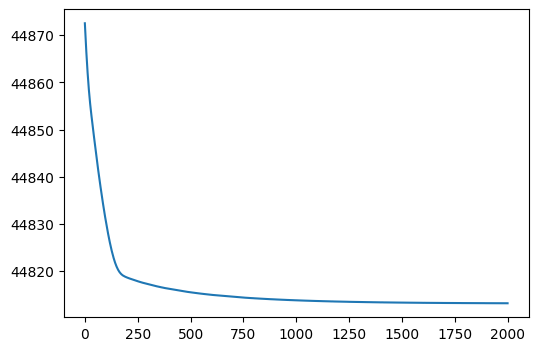

In [6]:
plt.rcParams["figure.figsize"] = (6, 4)

plt.plot(losses)
# plt.yscale('log');

In [16]:
params.keys()

dict_keys(['p_mix_auto_loc', 'p_rules_auto_loc'])

In [18]:
params["h_auto_loc"].shape

(50, 1, 5092)

In [9]:
params.keys()

dict_keys(['h_auto_loc', 'p_rules_auto_loc', 'y_prob_auto_loc'])

In [7]:
params["p_mix_auto_loc"]

Array(0.7499403, dtype=float32)

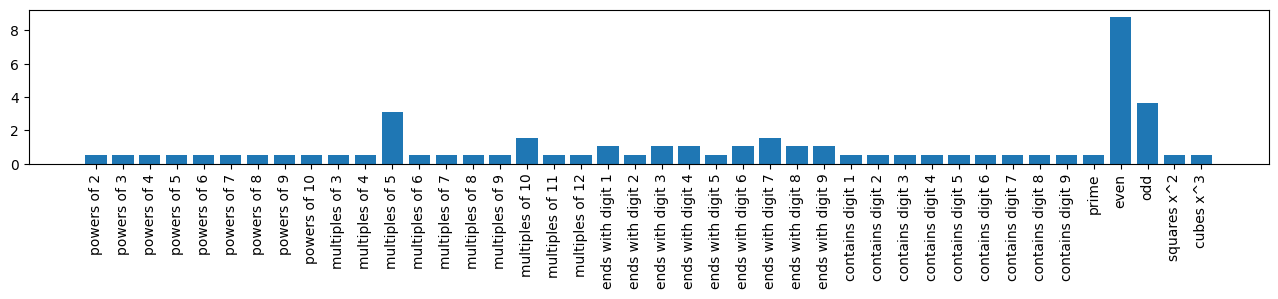

In [8]:
plt.rcParams["figure.figsize"] = (16, 2)

plt.bar(range(42), params["p_rules_auto_loc"])
plt.xticks(range(42), rule_concept_names, rotation=90)

### wrong model

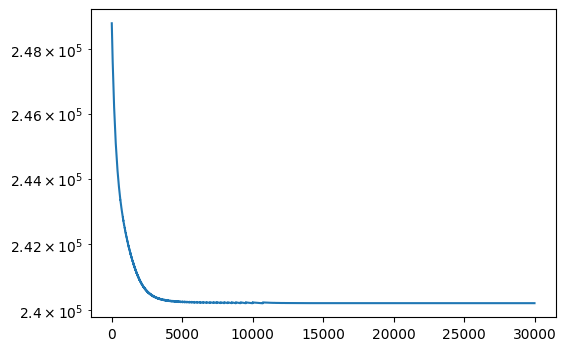

In [6]:
plt.rcParams["figure.figsize"] = (6, 4)

plt.plot(losses)
plt.yscale("log")

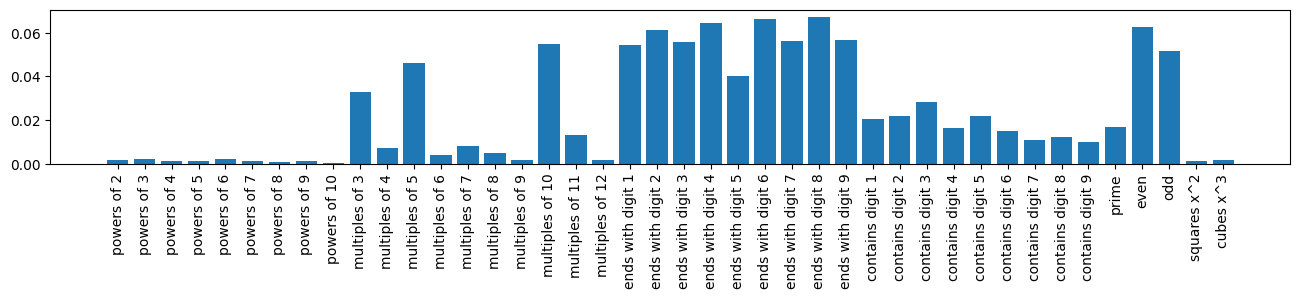

In [7]:
plt.rcParams["figure.figsize"] = (16, 2)

plt.bar(range(42), params["p_rules_auto_loc"])
plt.xticks(range(42), rule_concept_names, rotation=90)

### predictive

In [23]:
# use guide to make predictive
predictive = numpyro.infer.Predictive(
    model,
    guide=guide,
    params=params,
    num_samples=1000,
    return_sites=["y", "h", "y_pred"],
)
samples = predictive(
    rng_key, **model_kwargs
)  # **{k: v for k, v in model_kwargs.items() if k != 'obs_y'})

# # get posterior samples
# predictive = numpyro.infer.Predictive(guide, params=params, num_samples=1000)
# posterior_samples = predictive(rng_key, **model_kwargs)

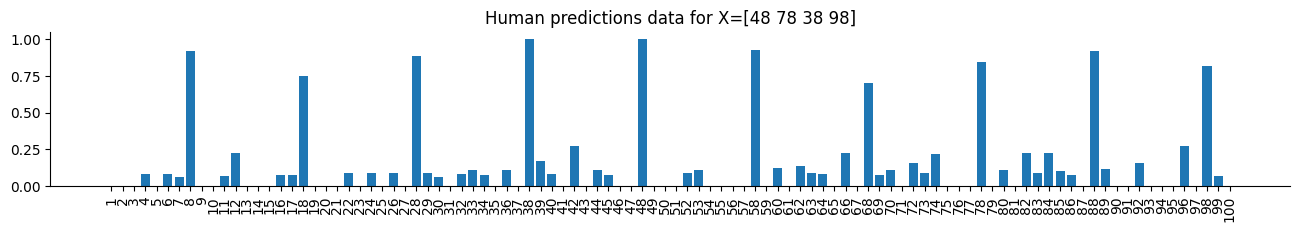

In [30]:
y_yes, y_total = obs_y[..., 0], obs_y[..., 1]

y_total.shape

i = 20
plt.bar(range(100), y_yes[i] / y_total[i])
plt.xticks(range(100), range(1, 101), rotation=90)

plt.title(f"Human predictions data for X={obs_X[i] + 1}")
sns.despine()

In [11]:
samples.keys()

dict_keys(['h', 'y', 'y_pred'])

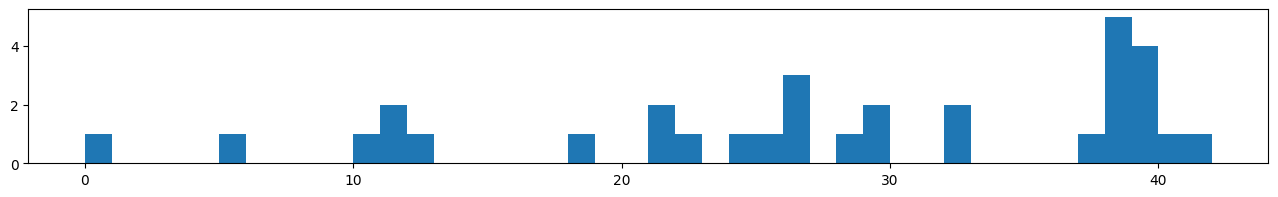

In [25]:
plt.hist(samples["h"][:42, 0, 0], bins=42, range=(0, 42))

In [13]:
samples["y_pred"].shape

(1000, 50, 1, 100)

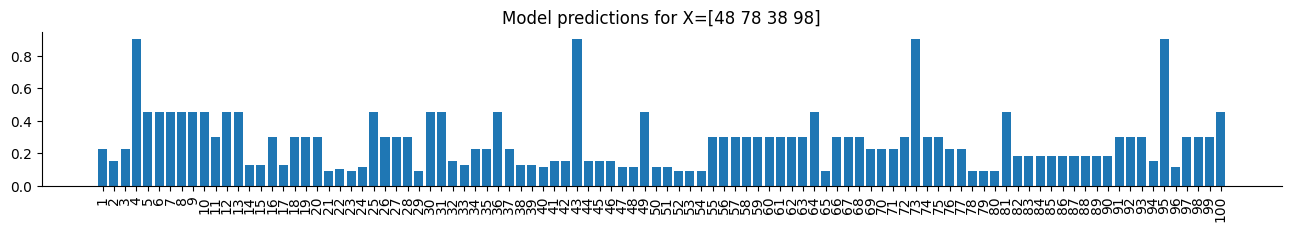

In [31]:
# y_est = jnp.max(samples['y'], axis=0)
# y_prob = samples['y_prob'].mean(axis=0)
y_prob = jnp.max(samples["y_pred"], axis=0)[:, 0, :]


i = 20
# plt.bar(range(100),  y_est[i] / y_total[i])
plt.bar(range(100), y_prob[i])
plt.xticks(range(100), range(1, 101), rotation=90)


plt.title(f"Model predictions for X={obs_X[i] + 1}")
sns.despine()

In [19]:
obs_X[i]

Array([47, 77, 37, 97], dtype=int32)

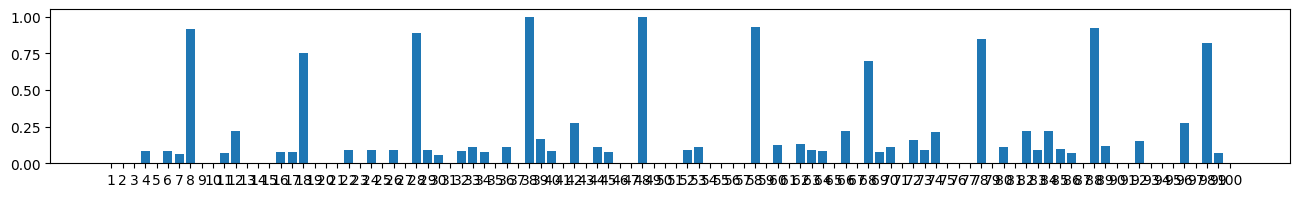

In [68]:
y_yes, y_total = obs_y[..., 0], obs_y[..., 1]

y_total.shape

i = 20
plt.bar(range(100), y_yes[i] / y_total[i])
plt.xticks(range(100), range(1, 101))